<a href="https://colab.research.google.com/github/maya300/Introduction_machine_learning/blob/main/Tutorial2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

# **Part I: Linear Classifier By Hand**

---



**1.1 Get the data**

In [ ]:
import sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

**1.2 Data pre-processing**

**1.2.1 Explore the Data**

In [ ]:
data_file = "ml_tutorial_2_calo_shower_data.csv"

df = pd.read_csv(data_file)

print("\n The columns are:", list(df.columns))
print("\n The labels are in column 'type'")

print("The number of samples is:", len(df))


 The columns are: ['shower_depth', 'shower_width', 'type']

 The labels are in column y
The number of samples is: 100000


**1.2.2 Labels to Binary**

In [ ]:
df['y'] = 0
df.loc[df['type'] == 'electron', 'y'] = 1

**1.2.3 Create Feature Matrix X**

In [ ]:
#Change to a numpy array
X = df[['shower_depth', 'shower_width']].to_numpy()
y = df['y'].to_numpy()

# Check shapes
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (100000, 2)
y shape: (100000,)


**1.2.4 Train/Test Split**

In [ ]:
from sklearn.model_selection import train_test_split

#Split into train data(80%) and test data(20%)
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.2, random_state=42
)
# Check shapes
print(f"X_train: {X_train.shape} y_train: {y_train.shape}")
print(f"X_test: {X_test.shape}, y_test: {y_test.shape}")

X_train: (80000, 2) y_train: (80000,)
X_test: (20000, 2), y_test: (20000,)


Yes, the shape make sense, because, we need to use a lot of data for the training.

**1.2.5 Feature Scaling**

**Which dataset(s) to scale?** Both the training and the test sets.

In [ ]:
# Get mean and std from training data
mean_train = X_train.mean(axis=0)
std_train = X_train.std(axis=0)

# Standardize training
X_train_scaled = (X_train - mean_train) / std_train
# Standardize test data (with the TRAINING mean and std)
X_test_scaled = (X_test - mean_train) / std_train

# Check
print("X_train_scaled mean:", X_train_scaled.mean(axis=0))
print("X_train_scaled std:", X_train_scaled.std(axis=0))

X_train_scaled mean: [-8.41370723e-15 -3.58326327e-14]
X_train_scaled std: [1. 1.]


**1.2.6 Feature Matrix Augmentation**

In [ ]:
X_train_aug = np.hstack((np.ones((X_train_scaled.shape[0], 1)), X_train_scaled))
X_test_aug = np.hstack((np.ones((X_test_scaled.shape[0], 1)), X_test_scaled))

print("X_train_aug:", X_train_aug.shape)
print("X_test_aug:", X_test_aug.shape)

X_train_aug: (80000, 3)
X_test_aug: (20000, 3)


**1.3 Functions**

**1.3.1 Hypothesis Function**

In [ ]:
def lin_sum(X, thetas):
    """
    Compute the linear combination of input features and parameters.

    Parameters
    ----------
    X : array-like, shape (m_samples, n_features+1)
        Input features (already augmented with a column of ones for bias).
    thetas : array-like, shape (n_features+1,) or (n_features+1, 1)
        Parameter vector including bias term.

    Returns
    -------
    ndarray, shape (m_samples, 1)
        Linear sum for each sample.
    """
    thetas = np.asarray(thetas).reshape(-1, 1)   # force a column vector (n+1, 1)
    return X @ thetas                            # (m, n+1) @ (n+1, 1) -> (m, 1)**

**1.3.2 Logistic Function**

 $\sigma(z) = \dfrac{1}{1+e^{-z}}$.

In [ ]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

**1.3.3 Partial Derivatives of Cross-Entropy Cost Function**

In [ ]:
def gradient_cross_entropy(y_true, y_pred, X):
    """
    Compute the gradient vector of the cross-entropy cost function.

    Parameters
    ----------
    y_true : array-like, shape (m,) or (m,1)
        Binary target (0 or 1) for each sample.
    y_pred : array-like, shape (m,) or (m,1)
        Predicted score for each sample.
    X : array-like, shape (m, n_features+1)
        Input features, already augmented with a column of ones for bias.

    Returns
    -------
    ndarray, shape (n_features+1, 1)
        Column vector of partial derivatives with respect to each model parameter.
    """
    m = X.shape[0]
    y_true = np.asarray(y_true).reshape(-1, 1)
    y_pred = np.asarray(y_pred).reshape(-1, 1)
    return (X.T @ (y_pred - y_true)) / m


# Dummy test: perfect predictions give a zero gradient
print(gradient_cross_entropy(np.array([1, 0]), np.array([1., 0.]), X_dummy))   # [[0],[0],[0]]
print(gradient_cross_entropy(np.array([1, 0]), np.array([0.5, 0.5]), X_dummy))  # shape (3, 1)

[[0.]
 [0.]
 [0.]]
[[ 0. ]
 [-0.5]
 [-1. ]]


**1.3.4 Cross-Entropy Cost Function**

In [ ]:
def cross_entropy_cost(y_true, y_pred):
    """
    Cross-entropy cost averaged over the samples.

    Parameters
    ----------
    y_true : array-like, shape (m,) or (m,1), binary targets
    y_pred : array-like, shape (m,) or (m,1), predicted scores in [0, 1]

    Returns
    -------
    float
    """
    y_true = np.asarray(y_true).reshape(-1, 1)
    y_pred = np.clip(np.asarray(y_pred).reshape(-1, 1), 1e-15, 1 - 1e-15)
    return float(-np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred)))


# Dummy test
print(cross_entropy_cost(np.array([1, 0]), np.array([0.5, 0.5])))   # ln(2) = 0.6931

0.6931471805599453


**1.4 Classifier Loop**

In [ ]:
def should_print_iteration(i, step_early, early_until, step_late):
    """True for every step_early-th iteration below early_until, then every step_late-th."""
    if i < early_until:
        return i % step_early == 0
    return i % step_late == 0

In [ ]:
# Hyperparameters
alpha = 0.5          # learning rate
N = 1000             # maximum number of iterations
epsilon = 1e-6       # tolerance threshold for gradient norm (stopping criterion)
cost_tol = 1e-8      # tolerance threshold for cost drop (stopping criterion)
cost_change = np.inf # initialize cost change for first iteration

# Number of features + 1 (number of columns in X)
n_param = X_train_aug.shape[1]

# Initialization of theta vector, shape (n_param, 1)
thetas = np.zeros((n_param, 1))

# Storing cost values for train and test datasets
costs_train = []
costs_test = []

print("Starting gradient descent\n")
# -------------------
# Start iterations
# -------------------
for iter_idx in range(N):

    # Get predictions (hypothesis function followed by the logistic function)
    y_pred_train = sigmoid(lin_sum(X_train_aug, thetas))   # (m_train, 1)
    y_pred_test = sigmoid(lin_sum(X_test_aug, thetas))     # (m_test, 1)

    # Calculate and store costs with train and test datasets
    cost_train = cross_entropy_cost(y_train, y_pred_train)
    cost_test = cross_entropy_cost(y_test, y_pred_test)
    costs_train.append(cost_train)
    costs_test.append(cost_test)

    # Gradient computation (training data only) & parameter update
    grad_cost_train = gradient_cross_entropy(y_train, y_pred_train, X_train_aug)  # (n_param, 1)
    grad_cost_norm = np.sqrt(grad_cost_train.T @ grad_cost_train)                 # (1, 1) array
    thetas = thetas - alpha * grad_cost_train

    # Cost change (for early stopping & printing)
    if iter_idx > 0:
        cost_change = cost_train - costs_train[-2]

    # Print selected iterations
    if should_print_iteration(iter_idx, 10, 100, 100):
        print(
            f"Iter {iter_idx:>4}\t"
            f"||grad|| = {grad_cost_norm.item():.4e}\t"
            f"Train cost = {cost_train:.5e}\t"
            f"Cost change = {cost_change:>+10.2e}\t"
            f"Test cost = {cost_test:.5e}"
        )

    # Exit conditions: gradient is small OR cost has plateaued
    # (use `and` instead of `or` for the more conservative dual criterion)
    if grad_cost_norm.item() < epsilon or abs(cost_change) < cost_tol:
        break

print(f'\nEnd of gradient descent after {iter_idx+1} iterations')
print('Optimized parameters:')
for j in range(len(thetas)):
    print(f'\tParameter {j} = {thetas[j,0]:.4f}')

Starting gradient descent

Iter    0	||grad|| = 4.2596e-01	Train cost = 6.93147e-01	Cost change =       +inf	Test cost = 6.93147e-01
Iter   10	||grad|| = 1.2537e-01	Train cost = 3.90283e-01	Cost change =  -8.83e-03	Test cost = 3.86889e-01
Iter   20	||grad|| = 7.0825e-02	Train cost = 3.44282e-01	Cost change =  -2.69e-03	Test cost = 3.39845e-01
Iter   30	||grad|| = 4.8295e-02	Train cost = 3.26753e-01	Cost change =  -1.23e-03	Test cost = 3.21701e-01
Iter   40	||grad|| = 3.5835e-02	Train cost = 3.17927e-01	Cost change =  -6.69e-04	Test cost = 3.12448e-01
Iter   50	||grad|| = 2.7881e-02	Train cost = 3.12845e-01	Cost change =  -4.03e-04	Test cost = 3.07047e-01
Iter   60	||grad|| = 2.2358e-02	Train cost = 3.09681e-01	Cost change =  -2.58e-04	Test cost = 3.03632e-01
Iter   70	||grad|| = 1.8306e-02	Train cost = 3.07606e-01	Cost change =  -1.72e-04	Test cost = 3.01356e-01
Iter   80	||grad|| = 1.5217e-02	Train cost = 3.06196e-01	Cost change =  -1.19e-04	Test cost = 2.99779e-01
Iter   90	||grad|| 

**1.5 Plot cost versus epochs**

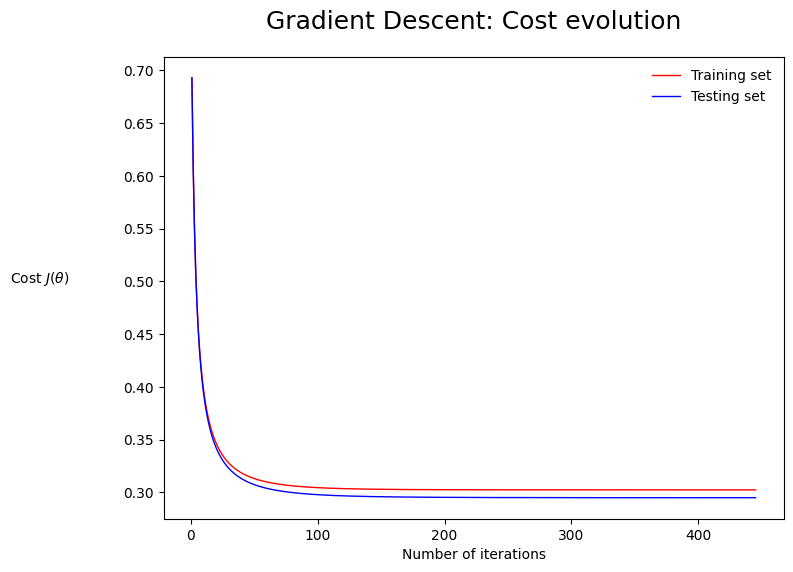

In [ ]:
def plot_cost_vs_iter(train_costs, test_costs,
                      title="Gradient Descent: Cost evolution"):

    fig, ax = plt.subplots(figsize=(8, 6))
    iters = np.arange(1, len(train_costs)+1)
    ax.plot(iters, train_costs, color='red', lw=1, label='Training set')
    ax.plot(iters, test_costs, color='blue', lw=1, label='Testing set')
    ax.set_xlabel("Number of iterations")
    ax.set_ylabel(r"Cost $J(\theta)$", rotation="horizontal")
    ax.yaxis.set_label_coords(-0.2, 0.5)
    ax.legend(loc="upper right", frameon=False)
    ax.set_title(title, fontsize=18, pad=20)
    plt.show()


plot_cost_vs_iter(costs_train, costs_test)

In [ ]:
!pwd

/content/gdrive/MyDrive/Machine_learning/Colab_Notebooks
